<a href="https://colab.research.google.com/github/irfan060606/Scikit-Learn-Cookbook/blob/main/Chapter_10_Clustering_Techniques.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 10 — Clustering Techniques (Teknik Clustering/Pengelompokan)

**Referensi:** *scikit-learn Cookbook, Third Edition* — John Sukup  
**Topik:** Unsupervised learning dan clustering dengan scikit-learn

Clustering adalah tugas **unsupervised learning**: algoritma mengelompokkan observasi berdasarkan nilai fiturnya tanpa mempelajari label target. Teknik ini dapat membantu mencari segmen pelanggan, mengelompokkan dokumen, menemukan pola, serta mengenali wilayah data yang padat atau titik noise.

Notebook ini mengikuti topik utama dalam bab:

1. Pengenalan clustering
2. K-Means
3. Hierarchical clustering
4. Clustering berbasis kepadatan dengan DBSCAN
5. Metrik evaluasi cluster
6. Memilih algoritma clustering yang sesuai
7. Teknik clustering lanjutan (Spectral Clustering dan Gaussian Mixture Models)

Bagian akhir berisi latihan menggunakan dataset Iris, data berbentuk bulan (*moons*), dan data berdimensi tinggi.

## Tujuan pembelajaran

Setelah menyelesaikan notebook ini, kamu diharapkan mampu:

- Menjelaskan perbedaan supervised learning dan clustering.
- Melatih serta memvisualisasikan K-Means, Agglomerative Clustering, dan DBSCAN.
- Menggunakan metode elbow dan metrik clustering untuk menilai hasil pengelompokan.
- Menjelaskan pengaruh bentuk cluster, noise, skala fitur, dan dimensionalitas dalam pemilihan algoritma.
- Membandingkan Spectral Clustering dengan Gaussian Mixture Models (GMM).

> **Penting:** ID cluster seperti `0`, `1`, dan `2` hanyalah penanda arbitrer. ID cluster tidak mempunyai makna bawaan; label dapat dipertukarkan tanpa mengubah kualitas pengelompokan.

## 10.1 Pengenalan clustering

Kita mulai dari data sintetis agar bentuk sebaran lebih mudah diperiksa. `make_blobs()` membuat kelompok di sekitar pusat tertentu. Label sengaja tidak digunakan pada visualisasi pertama karena clustering pada umumnya bekerja tanpa label yang diketahui.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 2024

X_blobs_raw, y_blobs_true = make_blobs(
    n_samples=300,
    centers=4,
    cluster_std=0.75,
    random_state=RANDOM_STATE,
)
X_blobs = StandardScaler().fit_transform(X_blobs_raw)

print("Jumlah observasi:", X_blobs.shape[0])
print("Jumlah fitur:", X_blobs.shape[1])
print("Rata-rata fitur setelah standardisasi:", np.round(X_blobs.mean(axis=0), 3))
print("Simpangan baku fitur setelah standardisasi:", np.round(X_blobs.std(axis=0), 3))

Jumlah observasi: 300
Jumlah fitur: 2
Rata-rata fitur setelah standardisasi: [ 0. -0.]
Simpangan baku fitur setelah standardisasi: [1. 1.]


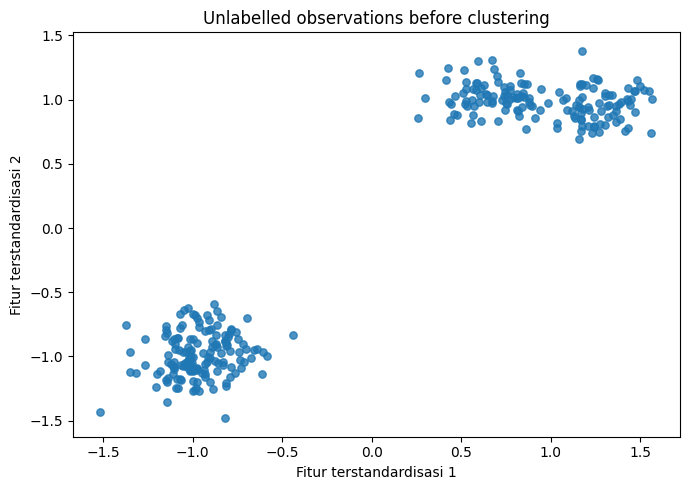

In [2]:
plt.figure(figsize=(7, 5))
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], s=28, alpha=0.8)
plt.title("Unlabelled observations before clustering")
plt.xlabel("Fitur terstandardisasi 1")
plt.ylabel("Fitur terstandardisasi 2")
plt.tight_layout()
plt.show()

### Mengapa fitur perlu diskalakan?

Banyak metode clustering mengandalkan jarak. Jika rentang numerik satu fitur jauh lebih besar daripada fitur lain, fitur tersebut dapat mendominasi perhitungan jarak. `StandardScaler` mengubah setiap fitur agar rata-ratanya mendekati nol dan variansnya mendekati satu. Scaling biasanya penting untuk K-Means, DBSCAN, serta metode berbasis jarak; model berbasis pohon mempunyai kebutuhan scaling yang berbeda.

Tiga cara umum melihat struktur cluster:

- **Berbasis centroid:** titik dikelompokkan di sekitar pusat (K-Means).
- **Berbasis keterhubungan:** cluster dibentuk dengan menggabungkan kelompok yang berdekatan secara bertahap (hierarchical clustering).
- **Berbasis kepadatan:** wilayah padat membentuk cluster, sedangkan titik di wilayah renggang dapat ditandai sebagai noise (DBSCAN).

## 10.2 K-Means Clustering

K-Means membagi data ke sejumlah cluster yang ditentukan, yaitu `k`. Algoritma berulang kali menempatkan setiap observasi ke centroid terdekat, kemudian memperbarui centroid menjadi rata-rata titik yang masuk ke cluster tersebut.

Fungsi tujuan yang sering disebut **inertia** atau jumlah kuadrat jarak dalam cluster adalah:

\[
J = \sum_{i=1}^{n} \left\|x_i - \mu_{c_i}
ight\|^2
\]

Di sini, \(\mu_{c_i}\) adalah centroid dari cluster yang ditetapkan untuk observasi \(i\). Inertia cenderung menurun ketika jumlah cluster bertambah, jadi jangan gunakan inertia saja untuk menentukan `k`.

In [3]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
labels_kmeans = kmeans.fit_predict(X_blobs)

print("Ukuran cluster:", np.bincount(labels_kmeans))
print(f"Inertia: {kmeans.inertia_:.3f}")
print("Iterasi hingga konvergen:", kmeans.n_iter_)

Ukuran cluster: [83 77 73 67]
Inertia: 10.829
Iterasi hingga konvergen: 5


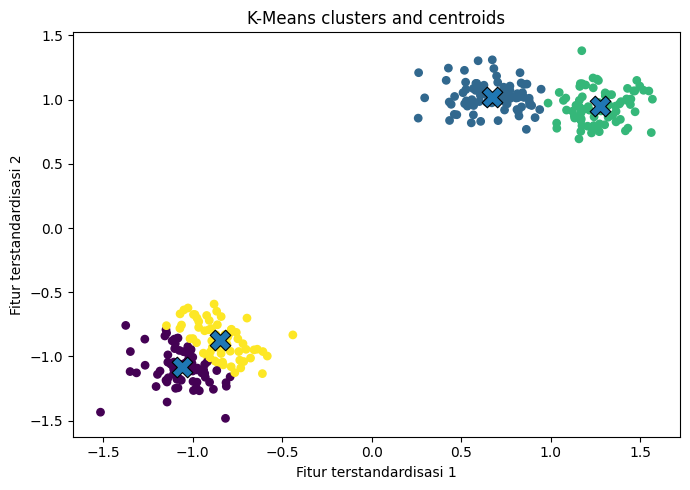

In [4]:
plt.figure(figsize=(7, 5))
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], c=labels_kmeans, cmap="viridis", s=28)
plt.scatter(
    kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
    marker="X", s=220, edgecolor="black", linewidth=0.8,
)
plt.title("K-Means clusters and centroids")
plt.xlabel("Fitur terstandardisasi 1")
plt.ylabel("Fitur terstandardisasi 2")
plt.tight_layout()
plt.show()

### Memilih `k`: metode elbow

Latih K-Means untuk beberapa nilai `k`, lalu buat grafik inertia terhadap `k`. Cari titik ketika penurunan inertia mulai melambat. Ini adalah panduan heuristik, bukan jawaban pasti: grafik mungkin tidak memiliki siku yang jelas dan nilai terbaik bergantung pada tujuan masalah serta bukti lain.

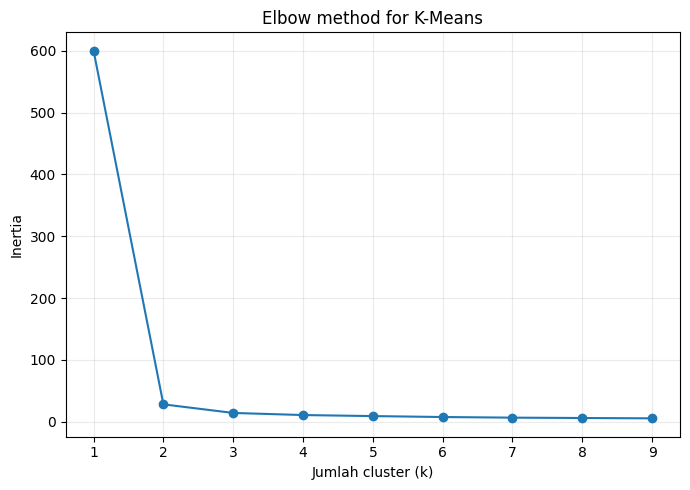

,k,inertia
0,1,600.000000
1,2,28.131937
2,3,14.225477
3,4,10.828969
4,5,9.148740
5,6,7.636177
6,7,6.623237
7,8,6.039043
8,9,5.501095


In [5]:
k_values = range(1, 10)
inertias = []
for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    model.fit(X_blobs)
    inertias.append(model.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xticks(list(k_values))
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("Inertia")
plt.title("Elbow method for K-Means")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

pd.DataFrame({"k": list(k_values), "inertia": inertias})

## 10.3 Hierarchical Clustering

Agglomerative hierarchical clustering dimulai dari observasi individual, lalu berulang kali menggabungkan cluster yang paling dekat. Pengaturan **linkage** menentukan cara menghitung jarak antarkelompok:

- `ward`: menggabungkan cluster dengan meminimalkan kenaikan varians dalam cluster (memerlukan jarak Euclidean).
- `complete`: memakai jarak pasangan maksimum antartitik pada dua cluster.
- `average`: memakai rata-rata jarak pasangan antartitik.
- `single`: memakai jarak pasangan minimum; dapat membentuk cluster memanjang seperti rantai.

Dendrogram memvisualisasikan hierarki penggabungan. Metode hierarkis berguna untuk memahami hubungan antarkelompok, tetapi algoritma agglomerative standar dapat membutuhkan biaya komputasi tinggi pada dataset besar.

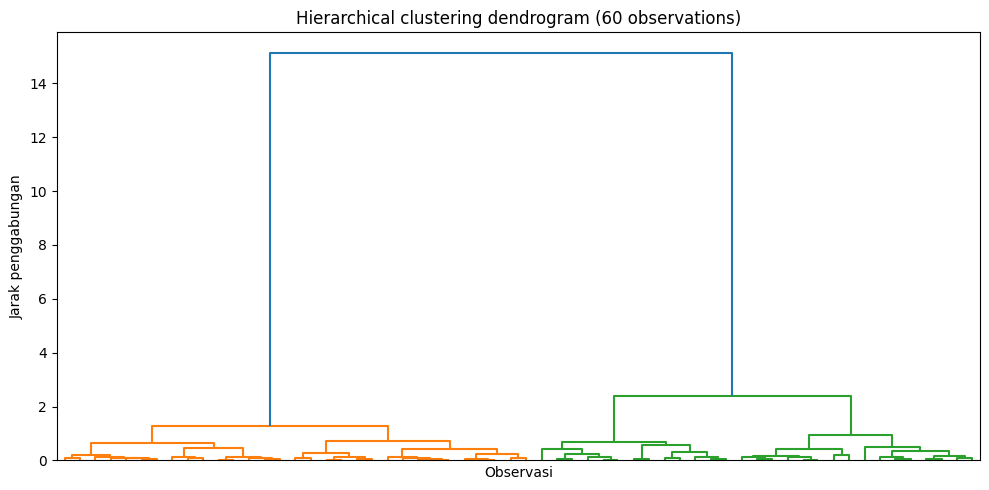

In [6]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram

# Gunakan subset agar dendrogram tetap mudah dibaca.
X_hier = X_blobs[:60]
Z = linkage(X_hier, method="ward")

plt.figure(figsize=(10, 5))
dendrogram(Z, no_labels=True, color_threshold=None)
plt.title("Hierarchical clustering dendrogram (60 observations)")
plt.xlabel("Observasi")
plt.ylabel("Jarak penggabungan")
plt.tight_layout()
plt.show()

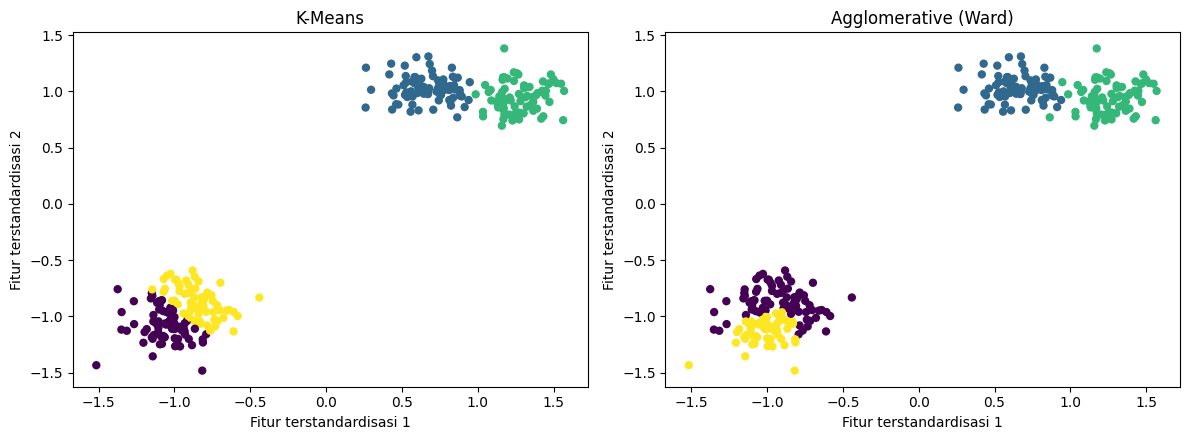

In [7]:
agg = AgglomerativeClustering(n_clusters=4, linkage="ward")
labels_agg = agg.fit_predict(X_blobs)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(X_blobs[:, 0], X_blobs[:, 1], c=labels_kmeans, cmap="viridis", s=25)
axes[0].set_title("K-Means")
axes[1].scatter(X_blobs[:, 0], X_blobs[:, 1], c=labels_agg, cmap="viridis", s=25)
axes[1].set_title("Agglomerative (Ward)")
for ax in axes:
    ax.set_xlabel("Fitur terstandardisasi 1")
    ax.set_ylabel("Fitur terstandardisasi 2")
plt.tight_layout()
plt.show()

## 10.4 Clustering berbasis kepadatan dengan DBSCAN

**DBSCAN** mengelompokkan titik di lingkungan yang padat dan dapat menandai titik yang terisolasi sebagai noise (`-1`). Parameter utamanya:

- `eps`: radius lingkungan.
- `min_samples`: jumlah titik tetangga minimum agar suatu wilayah dianggap padat.

Berbeda dari K-Means, DBSCAN tidak membutuhkan jumlah cluster di awal dan dapat menemukan bentuk yang tidak konveks. Namun, hasilnya dapat sensitif terhadap `eps`, `min_samples`, scaling fitur, dan dataset yang memiliki kepadatan lokal sangat berbeda.

In [8]:
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

X_moons_raw, y_moons_true = make_moons(
    n_samples=350, noise=0.08, random_state=RANDOM_STATE
)
X_moons = StandardScaler().fit_transform(X_moons_raw)

dbscan = DBSCAN(eps=0.22, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_moons)

n_clusters_db = len(set(labels_dbscan) - {-1})
n_noise = int(np.sum(labels_dbscan == -1))
print("Number of DBSCAN clusters:", n_clusters_db)
print("Jumlah titik yang diberi label noise:", n_noise)

Number of DBSCAN clusters: 2
Jumlah titik yang diberi label noise: 2


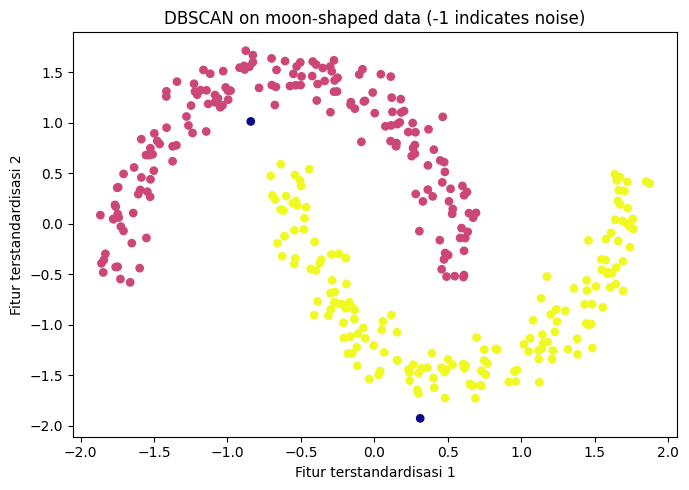

In [9]:
plt.figure(figsize=(7, 5))
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=labels_dbscan, cmap="plasma", s=28)
plt.title("DBSCAN on moon-shaped data (-1 indicates noise)")
plt.xlabel("Fitur terstandardisasi 1")
plt.ylabel("Fitur terstandardisasi 2")
plt.tight_layout()
plt.show()

### Menggunakan grafik k-distance untuk membantu memilih `eps`

Grafik k-distance menunjukkan jarak setiap titik ke tetangga terdekat ke-`k`, lalu mengurutkannya dari kecil ke besar. Perubahan kemiringan yang terlihat dapat menjadi perkiraan awal untuk `eps`; langkah ini tidak menggantikan pengujian beberapa kombinasi parameter yang masuk akal.

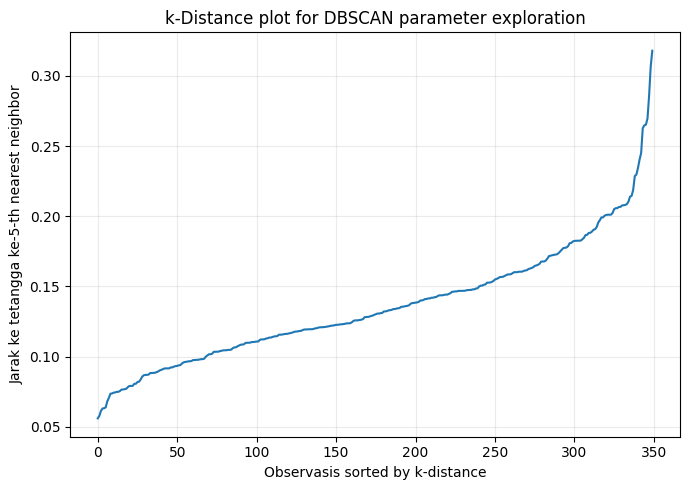

In [10]:
from sklearn.neighbors import NearestNeighbors

k_neighbors = 5
neighbors = NearestNeighbors(n_neighbors=k_neighbors).fit(X_moons)
distances, _ = neighbors.kneighbors(X_moons)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(7, 5))
plt.plot(k_distances)
plt.xlabel("Observasis sorted by k-distance")
plt.ylabel(f"Jarak ke tetangga ke-{k_neighbors}-th nearest neighbor")
plt.title("k-Distance plot for DBSCAN parameter exploration")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 10.5 Metrik evaluasi cluster

Clustering sering tidak memiliki label target yang diketahui, sehingga evaluasinya perlu dilakukan dengan hati-hati. Bagian ini menggunakan dua **metrik internal** dan satu **metrik eksternal** ketika label acuan tersedia:

- **Silhouette score:** berada pada rentang -1 sampai 1; nilai lebih besar umumnya lebih baik. Metrik ini membandingkan kekompakan di dalam cluster dengan jarak ke cluster terdekat lainnya.
- **Davies–Bouldin index:** nilai lebih rendah umumnya lebih baik; metrik ini merangkum kemiripan antarkelompok.
- **Adjusted Rand Index (ARI):** membandingkan hasil cluster dengan label acuan dan mengoreksi kecocokan yang dapat terjadi secara kebetulan; nilai 1 berarti cocok sempurna, sedangkan nilai mendekati 0 menunjukkan kecocokan setara peluang.

Tidak ada satu metrik yang sepenuhnya mewakili semua tujuan clustering. Pertimbangkan bentuk data, penanganan noise, ukuran cluster, dan penggunaan hasil pengelompokan.

In [11]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

# Metrik internal tidak menggunakan label sebenarnya.
silhouette = silhouette_score(X_blobs, labels_kmeans)
davies_bouldin = davies_bouldin_score(X_blobs, labels_kmeans)
# Metrik eksternal dapat digunakan karena label acuan data sintetis diketahui.
ari = adjusted_rand_score(y_blobs_true, labels_kmeans)

metrics_table = pd.DataFrame({
    "Metric": ["Silhouette score", "Davies-Bouldin index", "Adjusted Rand Index"],
    "Value": [silhouette, davies_bouldin, ari],
    "Preferred direction": ["Higher", "Lower", "Higher"],
})
metrics_table

,Metric,Value,Preferred direction
0,Silhouette score,0.483028,Higher
1,Davies-Bouldin index,0.811760,Lower
2,Adjusted Rand Index,0.746715,Higher


**Panduan interpretasi:** silhouette dan ARI yang lebih besar biasanya menunjukkan hasil yang lebih konsisten pada perbandingan ini; Davies–Bouldin index yang lebih rendah umumnya lebih baik. ARI hanya dapat digunakan jika label acuan memang tersedia. Pada tugas nyata tanpa label, label tersebut tidak akan diketahui.

Calinski–Harabasz index adalah ukuran internal lainnya, berdasarkan perbandingan sebaran antarkluster dengan sebaran di dalam cluster.

In [12]:
from sklearn.metrics import calinski_harabasz_score

calinski_harabasz = calinski_harabasz_score(X_blobs, labels_kmeans)
print(f"Indeks Calinski-Harabasz: {calinski_harabasz:.3f}")

Indeks Calinski-Harabasz: 5368.151


## 10.6 Memilih algoritma clustering yang tepat

Setiap algoritma memiliki asumsi yang berbeda. K-Means cenderung bekerja baik pada cluster kompak yang kira-kira konveks. DBSCAN sering lebih cocok untuk bentuk tidak beraturan dan data ber-noise. Hierarchical clustering berguna ketika hubungan antarkelompok perlu dipahami, sedangkan Spectral Clustering dapat merepresentasikan struktur non-konveks melalui graf kemiripan.

Eksperimen berikut membandingkan data blobs, moons, dan lingkaran konsentris. Tujuannya menunjukkan perilaku algoritma, bukan membuktikan bahwa satu metode selalu paling baik.

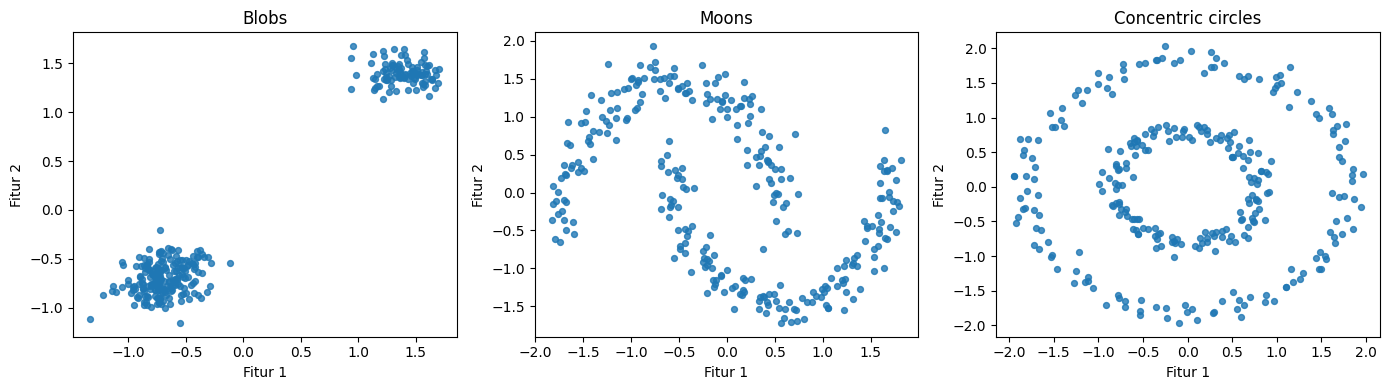

In [13]:
from sklearn.datasets import make_circles

X_blobs_choice, _ = make_blobs(n_samples=300, centers=3, cluster_std=0.65, random_state=RANDOM_STATE)
X_moons_choice, _ = make_moons(n_samples=300, noise=0.08, random_state=RANDOM_STATE)
X_circles_choice, _ = make_circles(n_samples=300, noise=0.05, factor=0.45, random_state=RANDOM_STATE)

datasets = [
    ("Blobs", StandardScaler().fit_transform(X_blobs_choice)),
    ("Moons", StandardScaler().fit_transform(X_moons_choice)),
    ("Concentric circles", StandardScaler().fit_transform(X_circles_choice)),
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, X_data) in zip(axes, datasets):
    ax.scatter(X_data[:, 0], X_data[:, 1], s=18, alpha=0.8)
    ax.set_title(name)
    ax.set_xlabel("Fitur 1")
    ax.set_ylabel("Fitur 2")
plt.tight_layout()
plt.show()

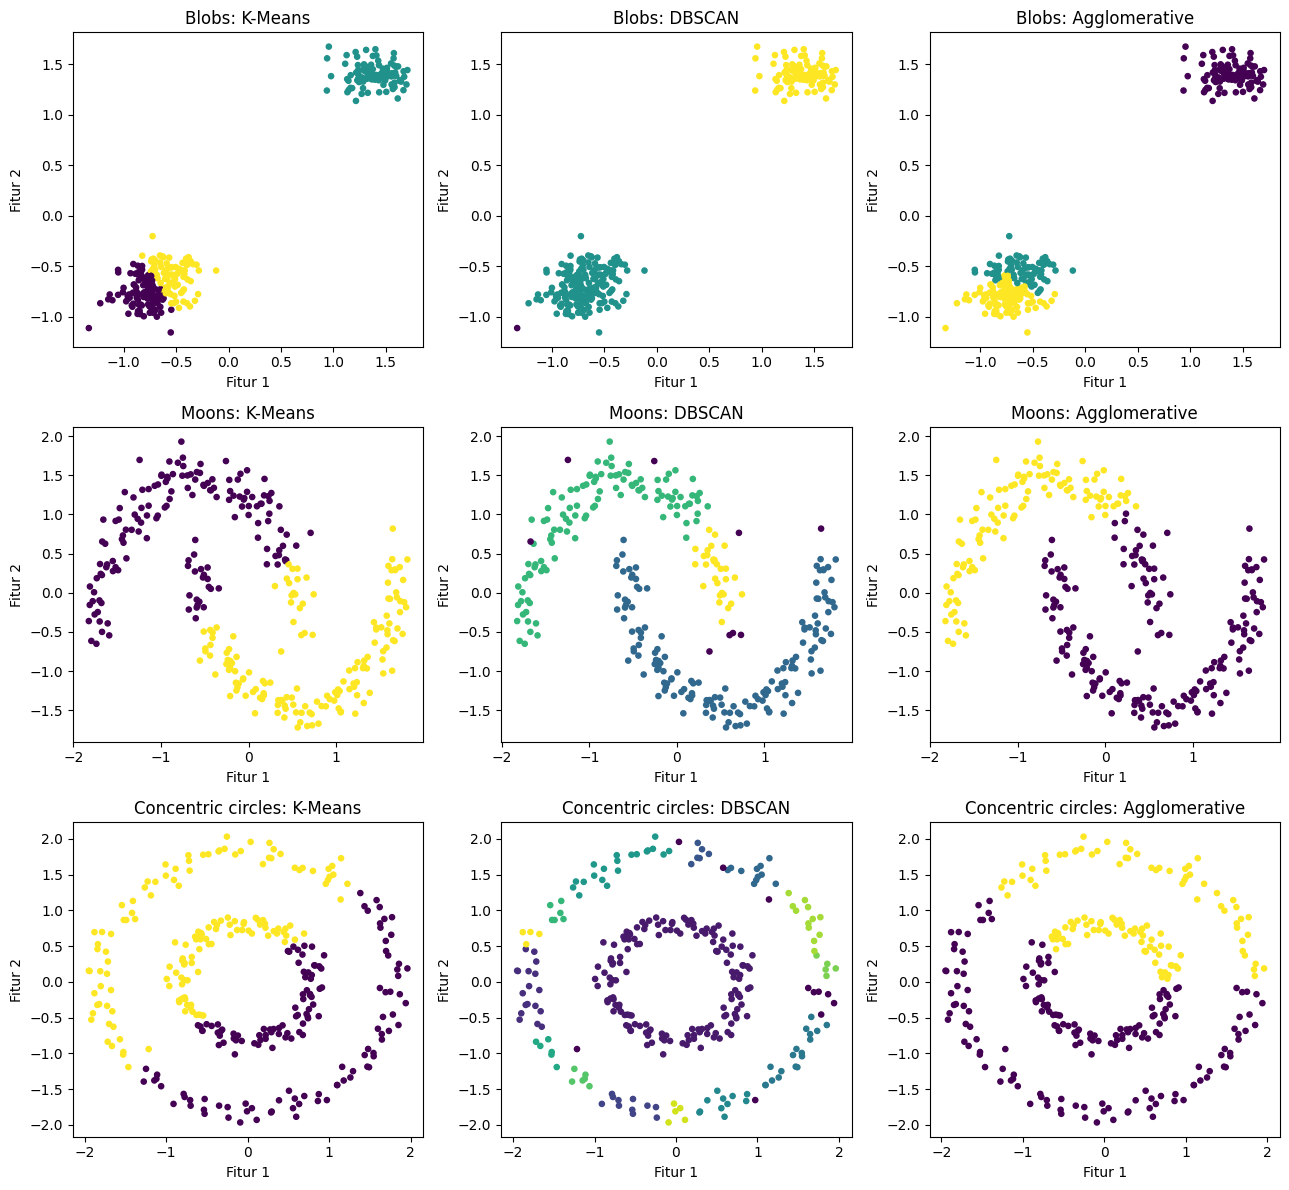

In [14]:
from sklearn.cluster import SpectralClustering

fig, axes = plt.subplots(len(datasets), 3, figsize=(13, 12))
for row, (name, X_data) in enumerate(datasets):
    predictions = [
        KMeans(n_clusters=2 if name != "Blobs" else 3, n_init=10, random_state=RANDOM_STATE).fit_predict(X_data),
        DBSCAN(eps=0.22, min_samples=5).fit_predict(X_data),
        AgglomerativeClustering(n_clusters=2 if name != "Blobs" else 3, linkage="ward").fit_predict(X_data),
    ]
    method_names = ["K-Means", "DBSCAN", "Agglomerative"]
    for col, (labels, method_name) in enumerate(zip(predictions, method_names)):
        axes[row, col].scatter(X_data[:, 0], X_data[:, 1], c=labels, cmap="viridis", s=14)
        axes[row, col].set_title(f"{name}: {method_name}")
        axes[row, col].set_xlabel("Fitur 1")
        axes[row, col].set_ylabel("Fitur 2")
plt.tight_layout()
plt.show()

Gunakan visualisasi untuk menjawab pertanyaan berikut: metode mana yang paling alami memisahkan data berbentuk bulan? Metode mana yang secara eksplisit menandai noise? Mengapa bentuk cluster penting? Jawaban bergantung pada dataset dan pemilihan parameter, jadi periksa grafik alih-alih hanya mengikuti aturan umum.

Panduan praktis dari bab ini:

| Karakteristik data | Algoritma awal yang layak dicoba |
|---|---|
| Cluster kompak dan kira-kira konveks | K-Means |
| Cluster melengkung atau non-konveks | DBSCAN atau Spectral Clustering |
| Noise atau titik terisolasi perlu dikenali | DBSCAN |
| Dataset kecil dan struktur hierarki berguna | Agglomerative Clustering |
| Dataset besar yang membutuhkan metode centroid berskala | K-Means atau MiniBatchKMeans |
| Fitur berdimensi tinggi | Pertimbangkan scaling dan reduksi dimensi seperti PCA |

## 10.7 Teknik clustering lanjutan

### Spectral Clustering

Spectral Clustering membangun representasi kemiripan antarsampel lalu mengelompokkan data pada ruang yang sudah ditransformasikan. Cara ini dapat membantu untuk struktur non-konveks yang sulit ditangani metode berbasis centroid. Biaya komputasi dan memorinya dapat meningkat saat ukuran dataset membesar.

### Gaussian Mixture Models (GMM)

GMM merepresentasikan data sebagai campuran beberapa komponen Gaussian. Berbeda dengan penetapan cluster yang tegas, `predict_proba()` memberikan perkiraan probabilitas setiap observasi berasal dari masing-masing komponen. Model dapat dibandingkan pada jumlah komponen berbeda menggunakan kriteria seperti AIC dan BIC; nilai lebih rendah lebih disukai ketika membandingkan model pada data yang sama dan dengan kriteria yang sama.

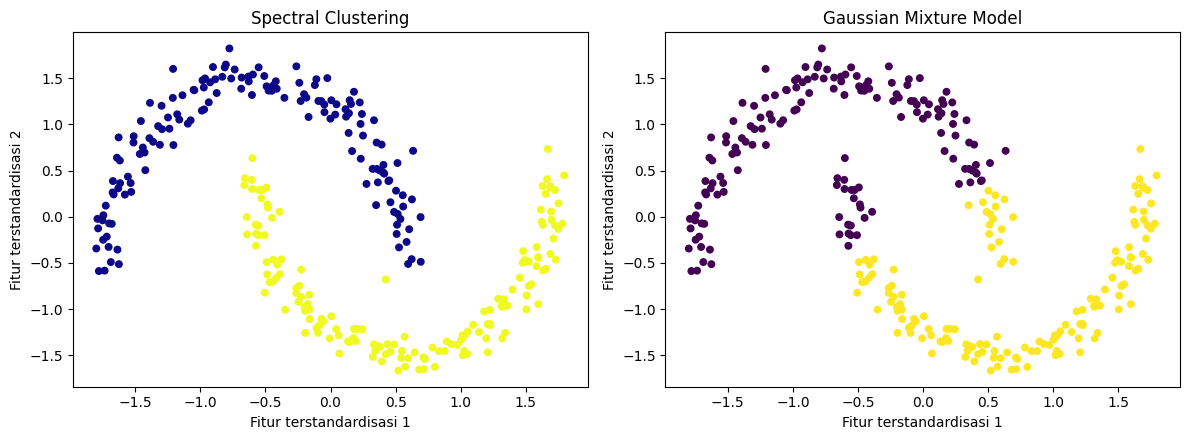

GMM konvergen: True
Iterasi GMM: 3
AIC GMM: 1558.71
BIC GMM: 1599.45


In [15]:
from sklearn.mixture import GaussianMixture

X_adv, _ = make_moons(n_samples=300, noise=0.06, random_state=RANDOM_STATE)
X_adv = StandardScaler().fit_transform(X_adv)

spectral = SpectralClustering(
    n_clusters=2, affinity="nearest_neighbors", n_neighbors=12,
    assign_labels="kmeans", random_state=RANDOM_STATE,
)
labels_spectral = spectral.fit_predict(X_adv)

gmm = GaussianMixture(n_components=2, covariance_type="full", random_state=RANDOM_STATE)
labels_gmm = gmm.fit_predict(X_adv)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(X_adv[:, 0], X_adv[:, 1], c=labels_spectral, cmap="plasma", s=22)
axes[0].set_title("Spectral Clustering")
axes[1].scatter(X_adv[:, 0], X_adv[:, 1], c=labels_gmm, cmap="viridis", s=22)
axes[1].set_title("Gaussian Mixture Model")
for ax in axes:
    ax.set_xlabel("Fitur terstandardisasi 1")
    ax.set_ylabel("Fitur terstandardisasi 2")
plt.tight_layout()
plt.show()

print(f"GMM konvergen: {gmm.converged_}")
print(f"Iterasi GMM: {gmm.n_iter_}")
print(f"AIC GMM: {gmm.aic(X_adv):.2f}")
print(f"BIC GMM: {gmm.bic(X_adv):.2f}")

In [16]:
probabilities = gmm.predict_proba(X_adv)
print("Ukuran matriks probabilitas:", probabilities.shape)
print("Lima baris probabilitas pertama:")
print(np.round(probabilities[:5], 3))

# Flag examples without a highly confident assignment (largest component probability < 0.70).
max_probability = probabilities.max(axis=1)
uncertain_count = int(np.sum(max_probability < 0.70))
print(f"Titik dengan probabilitas komponen maksimum di bawah 0,70: {uncertain_count} / {len(X_adv)}")

Ukuran matriks probabilitas: (300, 2)
Lima baris probabilitas pertama:
[[0.39  0.61 ]
 [0.051 0.949]
 [0.001 0.999]
 [1.    0.   ]
 [1.    0.   ]]
Titik dengan probabilitas komponen maksimum di bawah 0,70: 12 / 300


Probabilitas GMM menunjukkan ketidakpastian model atas komponen Gaussian. Nilai tersebut bukan probabilitas terverifikasi bahwa suatu sampel termasuk kelas dunia nyata tertentu; nilai itu bergantung pada model campuran yang sudah dilatih beserta asumsi-asumsinya.

## 10.8 Latihan praktis 1 — K-Means pada dataset Iris

Dataset Iris memiliki label spesies yang diketahui, tetapi kita akan melatih K-Means **tanpa menggunakan label tersebut**. Setelah itu, hasil pengelompokan dibandingkan dengan label spesies hanya untuk evaluasi eksternal. PCA digunakan untuk memproyeksikan empat fitur awal menjadi dua dimensi agar bisa divisualisasikan.

In [17]:
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA

iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)
y_iris_true = iris.target

iris_kmeans = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE)
y_iris_cluster = iris_kmeans.fit_predict(X_iris)
X_iris_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_iris)

print(f"Silhouette score: {silhouette_score(X_iris, y_iris_cluster):.3f}")
print(f"Adjusted Rand Index dibandingkan spesies: {adjusted_rand_score(y_iris_true, y_iris_cluster):.3f}")

Silhouette score: 0.460
Adjusted Rand Index dibandingkan spesies: 0.620


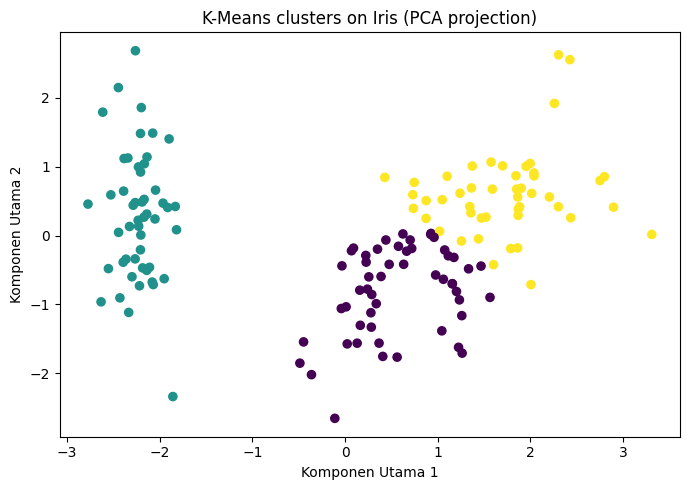

In [18]:
plt.figure(figsize=(7, 5))
plt.scatter(X_iris_pca[:, 0], X_iris_pca[:, 1], c=y_iris_cluster, cmap="viridis", s=35)
plt.title("K-Means clusters on Iris (PCA projection)")
plt.xlabel("Komponen Utama 1")
plt.ylabel("Komponen Utama 2")
plt.tight_layout()
plt.show()

## 10.9 Latihan praktis 2 — DBSCAN dibandingkan dengan K-Means pada data moons

Bandingkan kedua algoritma pada dataset non-konveks yang sama dan sudah diskalakan. Amati perbedaan asumsi K-Means yang berbasis centroid dengan pendekatan kepadatan DBSCAN. Ubah nilai `eps` pada DBSCAN dan jelaskan pengaruhnya terhadap jumlah cluster dan noise.

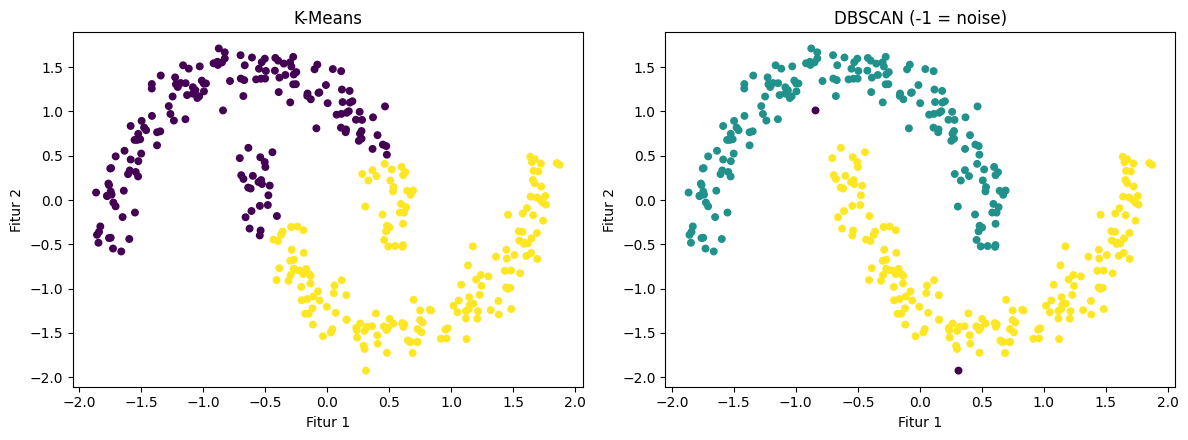

Label cluster DBSCAN (termasuk noise): [-1  0  1]


In [19]:
X_ex2, y_ex2_true = make_moons(n_samples=350, noise=0.08, random_state=RANDOM_STATE)
X_ex2 = StandardScaler().fit_transform(X_ex2)

ex2_kmeans = KMeans(n_clusters=2, n_init=10, random_state=RANDOM_STATE).fit_predict(X_ex2)
ex2_dbscan = DBSCAN(eps=0.22, min_samples=5).fit_predict(X_ex2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(X_ex2[:, 0], X_ex2[:, 1], c=ex2_kmeans, cmap="viridis", s=22)
axes[0].set_title("K-Means")
axes[1].scatter(X_ex2[:, 0], X_ex2[:, 1], c=ex2_dbscan, cmap="viridis", s=22)
axes[1].set_title("DBSCAN (-1 = noise)")
for ax in axes:
    ax.set_xlabel("Fitur 1")
    ax.set_ylabel("Fitur 2")
plt.tight_layout()
plt.show()

print("Label cluster DBSCAN (termasuk noise):", np.unique(ex2_dbscan))

## 10.10 Latihan praktis 3 — Clustering data berdimensi tinggi dengan PCA dan GMM

Latihan ini membuat data dengan banyak fitur, melakukan standardisasi, mengurangi dimensinya dengan PCA, lalu melatih GMM pada representasi PCA. Label hanya digunakan untuk evaluasi eksternal. PCA dapat menyederhanakan clustering, tetapi juga bisa membuang informasi; karena itu, bandingkan metrik dan jangan berasumsi bahwa jumlah komponen yang lebih sedikit selalu lebih baik.

In [20]:
from sklearn.datasets import make_classification

X_high, y_high_true = make_classification(
    n_samples=600,
    n_features=40,
    n_informative=8,
    n_redundant=8,
    n_repeated=0,
    n_classes=3,
    n_clusters_per_class=1,
    class_sep=1.5,
    random_state=RANDOM_STATE,
)
X_high_scaled = StandardScaler().fit_transform(X_high)

pca = PCA(n_components=0.90, random_state=RANDOM_STATE)
X_high_pca = pca.fit_transform(X_high_scaled)
print("Bentuk awal:", X_high_scaled.shape)
print("Bentuk PCA:", X_high_pca.shape)
print(f"Proporsi varians yang dipertahankan: {pca.explained_variance_ratio_.sum():.3f}")

Bentuk awal: (600, 40)
Bentuk PCA: (600, 26)
Proporsi varians yang dipertahankan: 0.910


Silhouette score (ruang PCA): 0.079
Adjusted Rand Index dibandingkan label buatan: 0.857


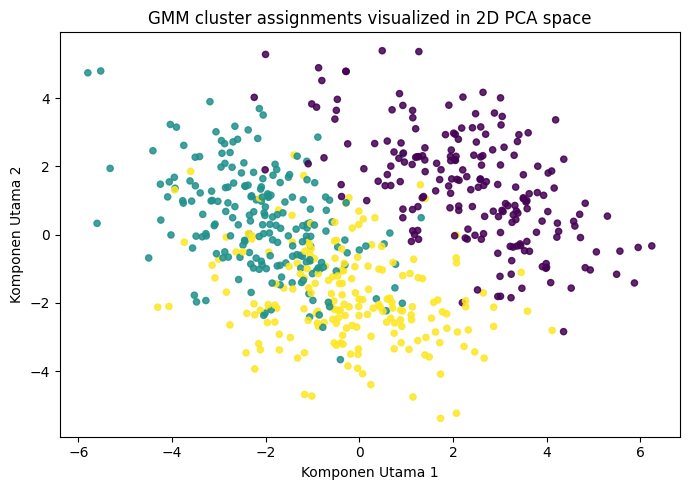

In [21]:
gmm_high = GaussianMixture(n_components=3, random_state=RANDOM_STATE)
labels_high = gmm_high.fit_predict(X_high_pca)

print(f"Silhouette score (ruang PCA): {silhouette_score(X_high_pca, labels_high):.3f}")
print(f"Adjusted Rand Index dibandingkan label buatan: {adjusted_rand_score(y_high_true, labels_high):.3f}")

X_high_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_high_scaled)
plt.figure(figsize=(7, 5))
plt.scatter(X_high_2d[:, 0], X_high_2d[:, 1], c=labels_high, cmap="viridis", s=20, alpha=0.85)
plt.title("GMM cluster assignments visualized in 2D PCA space")
plt.xlabel("Komponen Utama 1")
plt.ylabel("Komponen Utama 2")
plt.tight_layout()
plt.show()

## Pertanyaan tinjauan

Coba jawab tanpa menjalankan kode tambahan:

1. Mengapa K-Means membutuhkan nilai `n_clusters` sebelum pelatihan?
2. Apa yang dijelaskan oleh inertia, dan mengapa metode elbow hanya heuristik?
3. Bagaimana DBSCAN membedakan titik noise dari titik di wilayah padat?
4. Mengapa scaling fitur sering penting untuk K-Means dan DBSCAN?
5. Metrik mana yang bisa dihitung tanpa label acuan? Metrik mana yang membutuhkan label?
6. Apa perbedaan penetapan cluster yang tegas dengan probabilitas GMM?
7. Mengapa PCA dapat membantu sebelum clustering data berdimensi tinggi, dan apa konsekuensinya?

## Ringkasan dan poin penting

- **K-Means** sederhana dan dapat diskalakan untuk cluster kompak, tetapi membutuhkan nilai `k` dan bisa kesulitan dengan bentuk melengkung serta outlier.
- **Agglomerative Clustering** membangun hierarki penggabungan; pilihan linkage memengaruhi hasil cluster.
- **DBSCAN** dapat menemukan cluster padat dengan bentuk tidak beraturan serta menandai noise, tetapi sensitif terhadap parameter dan scaling fitur.
- **Silhouette**, **Davies–Bouldin**, dan **Calinski–Harabasz** memberi penilaian internal; **ARI** membandingkan cluster dengan label acuan yang diketahui.
- Tidak ada algoritma yang cocok untuk semua dataset. Periksa bentuk, kepadatan, noise, dan ukuran data sebelum memilih.
- **Spectral Clustering** berguna untuk sebagian struktur non-konveks. **GMM** memodelkan data secara probabilistik dan memberikan probabilitas keanggotaan lunak serta AIC/BIC untuk perbandingan model.
- Untuk data berdimensi tinggi, scaling dan reduksi dimensi seperti **PCA** dapat berguna, tetapi informasi yang dipertahankan tetap perlu diperiksa.

**Referensi:** John Sukup, *scikit-learn Cookbook, Third Edition*, Bab 10: “Clustering Techniques.”